# 01 — wcc_etc as an exposure time calculator

`wcc_etc` is the exposure time calculator (ETC) for the **Wide-field Context Camera (WCC)** on the
Lazuli Space Observatory: a 3.065 m unobscured telescope feeding a Sony IMX455 CMOS sensor at
**16.9 mas per pixel**, with u, g, r, i, z, a wide "bb" filter and three H-alpha filters.
The first thing it is used for is to answer *"what SNR do I get in t seconds, and how long do I
need for SNR = 10?"*

A **web version** of the same calculator is at <https://simulators.schmidtobservatorysystem.org/wcc/>:
use it for a quick number, and these notebooks when you want sweeps, plots, your own spectra and
simulated images.

In this notebook:
1. a scene and a simulation: `get_scene()` and `Simulation.from_sensorfilter()`,
2. SNR for an exposure time, and exposure time for an SNR,
3. sweeps over exposure time and magnitude, and the 5 sigma limiting magnitude,
4. the sensor:filter labels.

**Jupyter AI.** These notebooks are written to be run with the Jupyter AI chat open in the side
panel (the sparkle icon). Boxes marked 🤖 suggest things to ask it. It can see the cell you have
selected, so "explain this cell" or pasting a traceback works well. Boxes marked ✏️ ask you to guess
a number before computing it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wcc_etc
from wcc_etc import Simulation, get_scene

wcc_etc.set_wcc_style()

***
## 1. A scene and a simulation

A **scene** is a source (a spectrum with a magnitude), optionally a host galaxy, and a background
(zodiacal light by default). A **simulation** is a scene on a telescope + sensor + filter.
The label `"zwo:r"` means the IMX455 sensor (ZWO camera) in the r filter.

`get_scene` normalizes to Johnson V (Vega) unless told otherwise: always give `bandpass` and
`magsys` explicitly, here SDSS r in AB.

In [2]:
scene = get_scene("G2V", mag=20, bandpass="sdss_r", magsys="abmag")
sim = Simulation.from_sensorfilter("zwo:r", scene)
sim.describe()

  time: 90
  n_reads: 1
  telescope: {'diameter_primary': 3.065, 'f_num': 15.0, 'jitter_sigma': 10}
  sensor: {'pixel_size': 3.76, 'gain_setting': 100, 'sensor_temp': 0.0, 'sensor_area': 864, 'bias_level': 0, 'bit_depth': 16, 'min_frame_time': 0.25, 'path_dark_current': 'sensors/ZWO_ASI6200MM/ZWO_ASI6200MM_Pro_Dark_Current_vs_Sensor_Temperature.csv', 'path_gain_curve': 'sensors/ZWO_ASI6200MM/ZWO_ASI6200MM_Pro_Gain_vs_Gain_Setting.csv', 'path_read_noise': 'sensors/ZWO_ASI6200MM/ZWO_ASI6200MM_Pro_Read_Noise_vs_Gain_Setting.csv', 'path_well_depth': 'sensors/ZWO_ASI6200MM/ZWO_ASI6200MM_Pro_Well_Depth_vs_Gain_Setting.csv', 'read_noise_margin': 2.0, 'path_qe': '', 'path_total_throughput': 'throughput/20260304_wcc_throughputs/wcc_imx_r_throughput.csv', 'read_noise': np.float64(3.0442890448219115), 'dark_current': np.float64(0.0030703367499985944), 'gain': np.float64(0.261200000004368), 'area': <Quantity 864. mm2>, 'temperature': <Quantity 0. deg_C>, 'qe': 1, 'well_depth': np.float64(16274.929

`describe()` lists everything the calculation uses: the 3.065 m aperture, the 10 mas pointing
jitter, the sensor read noise, dark current and well depth at this gain setting, and the scene.

***
## 2. SNR for an exposure time, exposure time for an SNR

`get_image_snr(t)` renders the PSF on the pixel grid, places an aperture on it, and returns a
dictionary. `snr` is the number you want; the others say how it was obtained.

In [3]:
r = sim.get_image_snr(60)
for k, v in r.items():
    print(f"{k:18s} {v}")

snr                140.38339554850847
signal_e           20276.48918103915
noise_e            144.4365204432796
enclosed_fraction  0.8822771284602666
r_aper_mas         69.55303873461186
n_pix              57
n_saturated        0
saturated          False
read_noise_e       3.0442890448219115


[wcc_etc] note: even n_pixels is rounded up by 1 to center the PSF peak (shown once).


- `signal_e`, `noise_e`: electrons in the aperture, and the noise (photon + background + dark + read).
- `r_aper_mas`, `n_pix`, `enclosed_fraction`: the aperture (radius in milliarcseconds, pixels inside,
  fraction of the PSF it encloses). Notebook 04 shows how to change it.
- `saturated`, `n_saturated`: whether any pixel exceeds the well depth. Notebook 02 is about this.

The inverse question, the exposure time for a target SNR:

In [4]:
r10 = sim.get_image_exptime_for_snr(10)
r100 = sim.get_image_exptime_for_snr(100)
print(f"SNR = 10 in {r10['time_s']:.2f} s, SNR = 100 in {r100['time_s']:.1f} s (ratio {r100['time_s'] / r10['time_s']:.0f})")

SNR = 10 in 0.84 s, SNR = 100 in 31.2 s (ratio 37)


A factor 10 in SNR costs a factor ~100 in time, as expected when the source dominates the noise
($\mathrm{SNR} \propto \sqrt{t}$). Notebook 02 shows when it does not.

***
## 3. Sweeps: SNR versus exposure time and magnitude

The simulation has plot helpers for the common sweeps. `plot_snr` takes an array of exposure times.

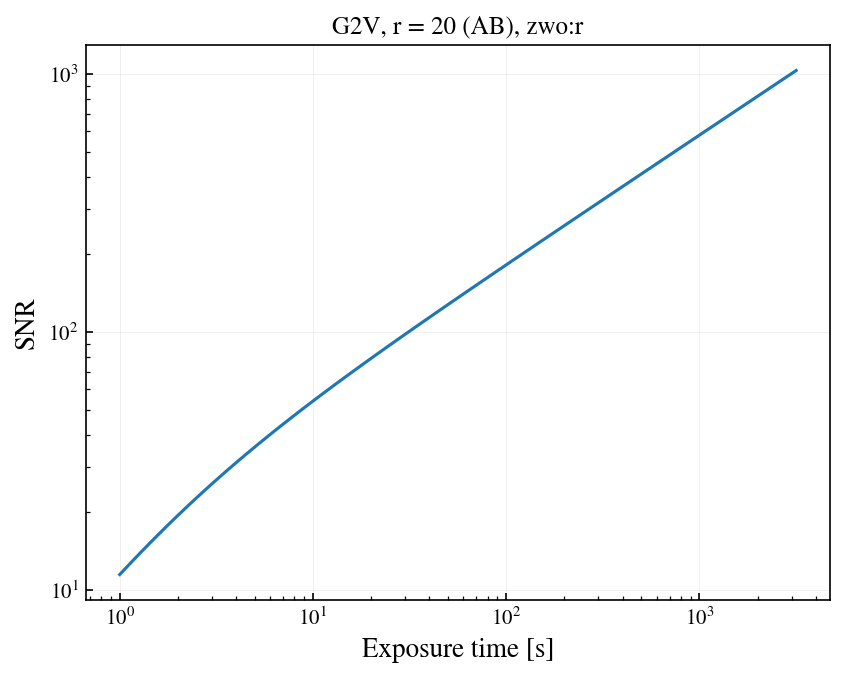

In [5]:
fig, ax = sim.plot_snr(np.logspace(0, 3.5, 60))
ax.set(xscale="log", yscale="log", title="G2V, r = 20 (AB), zwo:r")
plt.show()

Passing `mags=` to `get_image_snr` sweeps the source magnitude at fixed exposure time: the result
dictionary then holds arrays. The 5 sigma **limiting magnitude** is where the SNR curve crosses 5.
`limiting_mag` below interpolates that crossing; it returns NaN rather than a guess when the
curve is saturated or does not bracket the target. Keep this helper, the exercises use it.

In [6]:
def limiting_mag(sim, t, snr_target=5, mags=np.arange(16, 32.01, 0.25), **kw):
    """Magnitude at which the SNR in t seconds falls to snr_target; NaN if saturated or not bracketed."""
    r = sim.get_image_snr(t, mags=mags, warn=False, **kw)
    snr = np.where(r["saturated"], np.nan, r["snr"])
    ok = np.isfinite(snr)
    if ok.sum() < 2 or not (snr[ok].max() > snr_target > snr[ok].min()):
        return np.nan
    return float(np.interp(np.log10(snr_target), np.log10(snr[ok][::-1]), mags[ok][::-1]))

> ✏️ **Before you run the next cell:** what is the 5 sigma point-source depth of WCC in r in a single 300 s exposure? (AB magnitude) Write your guess down (or put it in the room poll), then run.

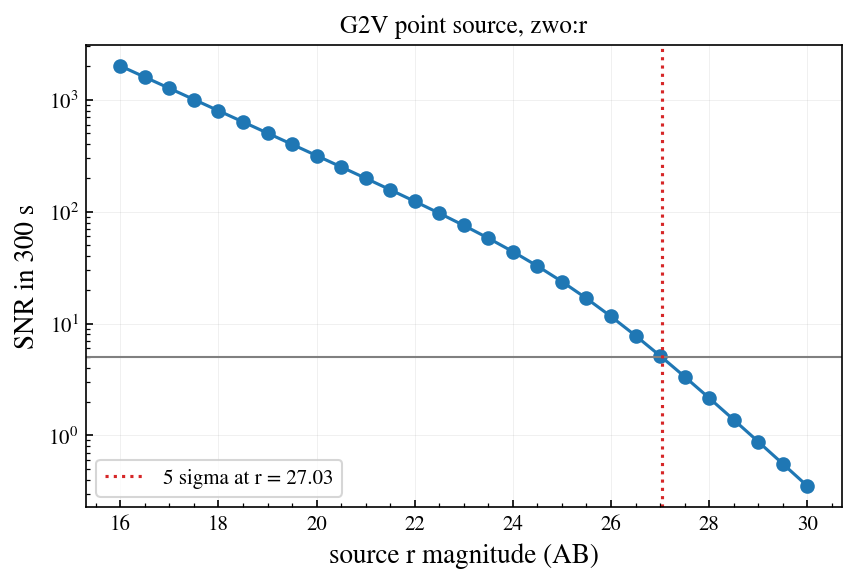

5 sigma depth in 300 s: r = 27.03 (AB)


In [7]:
mags = np.arange(16, 30.01, 0.5)
t = 300
r = sim.get_image_snr(t, mags=mags, warn=False)
depth = limiting_mag(sim, t)

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.semilogy(mags, r["snr"], "o-")
ax.axhline(5, color="0.5", lw=1)
ax.axvline(depth, color="C3", ls=":", label=f"5 sigma at r = {depth:.2f}")
ax.set(xlabel="source r magnitude (AB)", ylabel=f"SNR in {t} s", title="G2V point source, zwo:r")
ax.legend()
plt.show()
print(f"5 sigma depth in {t} s: r = {depth:.2f} (AB)")

***
## 4. The sensor:filter labels

`from_sensorfilter` accepts these labels (an unknown label raises an error that lists them):

| label | sensor | filter | PSF |
|---|---|---|---|
| `zwo:u` `zwo:g` `zwo:r` `zwo:i` `zwo:z` | IMX455 | SDSS-like broadband | in focus |
| `zwo:bb` | IMX455 | wide "bb" filter | in focus |
| `zwo:halpha2` `zwo:halpha6` `zwo:halpha20` | IMX455 | H-alpha, 20 / 60 / 200 Å wide | in focus |
| `zwo:r+1` `zwo:r-1` | IMX455 | r | defocused by 1 wave (notebook 04) |
| `zwo:bb2` | IMX455 | bb | defocused by 2 waves |
| `qcmos:u` `qcmos:g` `qcmos:i` `qcmos:z` `qcmos:bb` | Hamamatsu qCMOS | broadband | in focus |

The same scene in one other filter:

In [8]:
sim_g = Simulation.from_sensorfilter("zwo:g", scene)
print(f"zwo:g: 5 sigma depth in 300 s = {limiting_mag(sim_g, 300):.2f} (AB)")

zwo:g: 5 sigma depth in 300 s = 27.28 (AB)


> 🤖 **Ask Jupyter AI:** *Turn the cell above into a loop over zwo:u, zwo:g, zwo:r, zwo:i, zwo:z and zwo:bb, and print a table of the 5 sigma depth in 300 s with the filter pivot wavelength.*
>
> Then compare with the next cell, which also draws the filter curves.

filter   pivot [A] 5 sigma, 300 s


zwo:u         3765          23.78


zwo:g         4773          27.28
zwo:r         6140          27.03


zwo:i         7610          26.13
zwo:z         9012          25.03


zwo:bb        5821          27.87


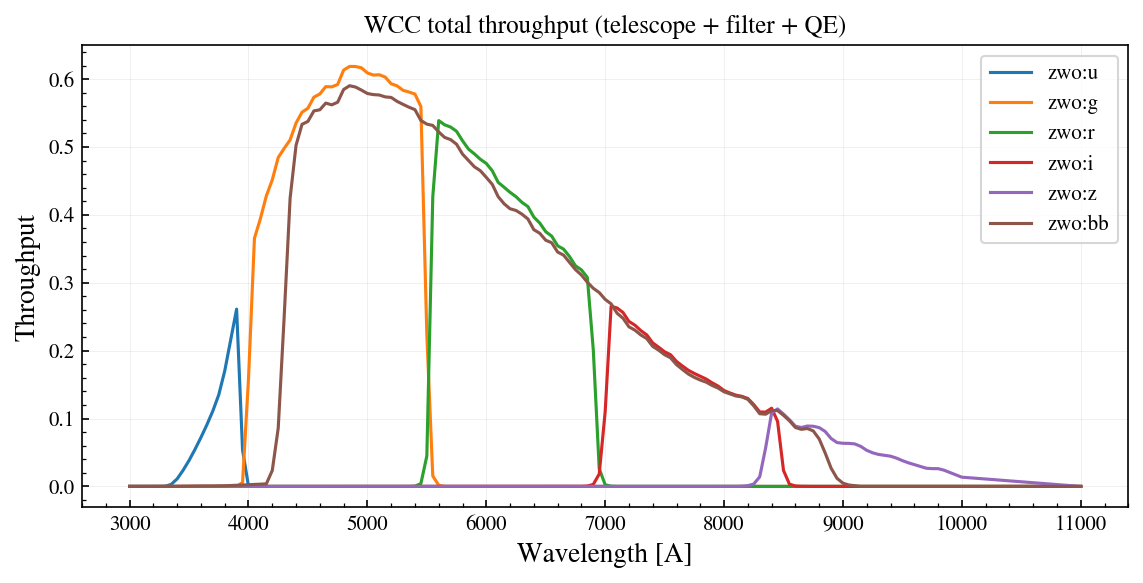

In [9]:
filters = ["zwo:u", "zwo:g", "zwo:r", "zwo:i", "zwo:z", "zwo:bb"]
fig, ax = plt.subplots(figsize=(9, 4))
print(f"{'filter':8s} {'pivot [A]':>9s} {'5 sigma, 300 s':>14s}")
for f in filters:
    s = Simulation.from_sensorfilter(f, scene)
    wcc_etc.plot_bandpass_mpl(s.sensor, ax=ax, label=f)
    print(f"{f:8s} {s.sensor.bandpass.pivot().value:9.0f} {limiting_mag(s, 300):14.2f}")
ax.set(title="WCC total throughput (telescope + filter + QE)")
ax.legend()
plt.show()

***
## Summary

```python
scene = get_scene("G2V", mag=20, bandpass="sdss_r", magsys="abmag")   # source (+ host, + background)
sim   = Simulation.from_sensorfilter("zwo:r", scene)                   # on the WCC, in a filter
sim.get_image_snr(60)["snr"]                                           # SNR in 60 s
sim.get_image_exptime_for_snr(10)["time_s"]                            # seconds for SNR = 10
sim.get_image_snr(300, mags=np.arange(16, 30))["snr"]                  # a magnitude sweep
sim.update(source__mag=22)                                             # change anything, then recompute
```

Next: [02 — the detector](02_detector_saturation_reads.ipynb), where bright stars saturate.